Assignment: Data Visualization with Matplotlib

In [ ]:
# Imports what we need
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Display plots directly in the notebook
get_ipython().run_line_magic('matplotlib', 'inline')

# Load the four data files. Gives a message if a file is missing.
try:
    sales = pd.read_csv('sales-data.csv')
    products = pd.read_csv('product-performance.csv')
    customers = pd.read_csv('customer-data.csv')
    competitors = pd.read_csv('competitor-analysis.csv')
    print('All files loaded.')
except FileNotFoundError as e:
    print('Missing file - make sure the CSVs are in the same folder as this notebook.')
    print(e)

All files loaded.


Task 1: Sales Trend Analysis

Task 1.1
Create a line plot showing monthly sales for 2023 and 2024
Include proper styling (colors, markers, line styles)
Add a title, axis labels, and legend
Include grid lines for better readability
Format the y-axis to show dollar amounts

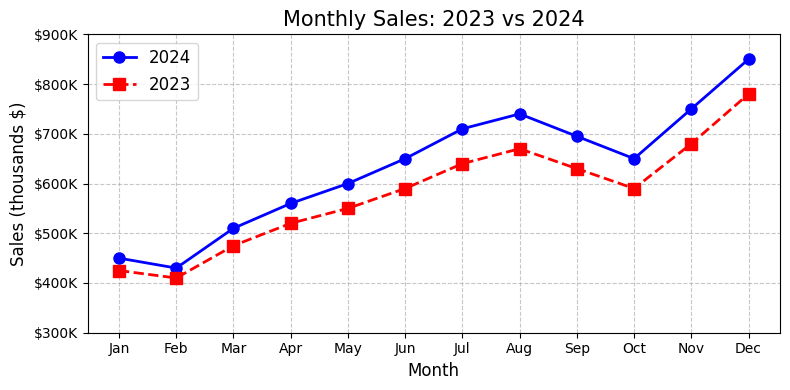

In [ ]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sales_2023 = sales[sales['Year'] == 2023]['Sales'].values / 1000
sales_2024 = sales[sales['Year'] == 2024]['Sales'].values / 1000

ig, ax = plt.subplots(figsize=(8, 4))

# Two lines with different colors, line styles, and markers
ax.plot(month_names, sales_2024, color='blue', linestyle='-', marker='o',
        linewidth=2, markersize=8, label='2024')
ax.plot(month_names, sales_2023, color='red', linestyle='--', marker='s',
        linewidth=2, markersize=8, label='2023')

# Title, axis labels, and legend
ax.set_title('Monthly Sales: 2023 vs 2024', fontsize=15)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Sales (thousands $)', fontsize=12)
ax.legend(fontsize=12)

# Grid lines
ax.grid(True, linestyle='--', alpha=0.7)

# Y-axis formatted as dollars
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels([f'${x:,.0f}K' for x in ax.get_yticks()])

plt.tight_layout()
plt.show()

Task 1.2
Create a bar chart comparing quarterly sales for 2023 and 2024
Use different colors for each year
Add data labels showing the percentage change between years
Include a title and appropriate axis labels

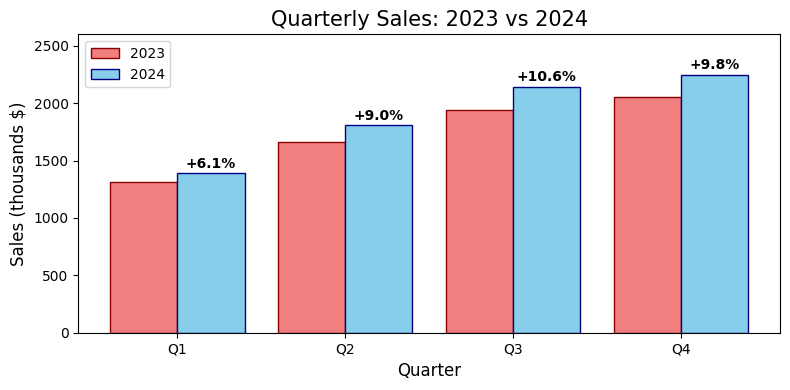

In [ ]:
# Add up every 3 months to get quarterly totals
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
q_2023 = sales_2023.reshape(4, 3).sum(axis=1)
q_2024 = sales_2024.reshape(4, 3).sum(axis=1)
pct_change = (q_2024 - q_2023) / q_2023 * 100

x = np.arange(len(quarters))  # bar positions
width = 0.4

fig, ax = plt.subplots(figsize=(8, 4))

# Side-by-side bars, a different color for each year
ax.bar(x - width/2, q_2023, width, color='lightcoral', edgecolor='darkred', label='2023')
bars = ax.bar(x + width/2, q_2024, width, color='skyblue', edgecolor='navy', label='2024')

# Data labels showing % change above each 2024 bar
for bar, pct in zip(bars, pct_change):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 20,
            f'+{pct:.1f}%', ha='center', va='bottom', fontweight='bold')

# Title and axis labels
ax.set_title('Quarterly Sales: 2023 vs 2024', fontsize=15)
ax.set_xlabel('Quarter', fontsize=12)
ax.set_ylabel('Sales (thousands $)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(quarters)
ax.set_ylim(0, 2600)  # start at zero, leave room for labels
ax.legend()

plt.tight_layout()
plt.show()

Task 1.3 Create a line plot showing the cumulative sales for both years
Add annotations highlighting key points (e.g., when 2024 sales surpassed 2023)
Include a title, axis labels, and legend

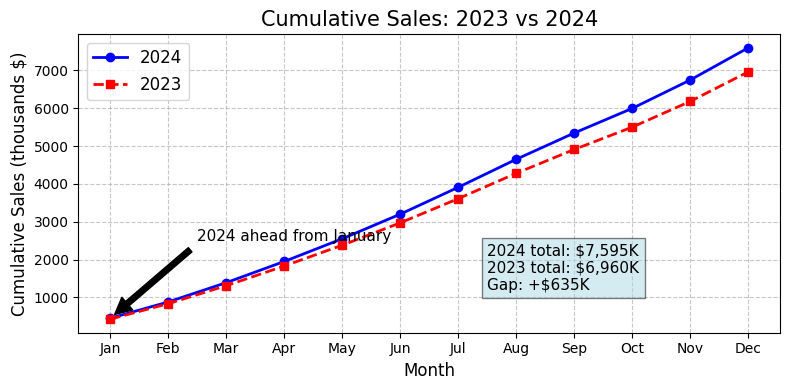

In [ ]:
# Running totals
cum_2023 = np.cumsum(sales_2023)
cum_2024 = np.cumsum(sales_2024)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(month_names, cum_2024, color='blue', marker='o', linewidth=2, label='2024')
ax.plot(month_names, cum_2023, color='red', marker='s', linestyle='--', linewidth=2,
        label='2023')

# Annotation
ax.annotate('2024 ahead from January', xy=(0, cum_2024[0]), xytext=(1.5, 2500),
            arrowprops=dict(facecolor='black', shrink=0.05), fontsize=11)

# Annotation
gap = cum_2024[-1] - cum_2023[-1]
ax.text(6.5, 1200,
        f'2024 total: ${cum_2024[-1]:,.0f}K\n2023 total: ${cum_2023[-1]:,.0f}K\nGap: +${gap:,.0f}K',
        fontsize=11, bbox=dict(facecolor='lightblue', alpha=0.5))

# Title, axis labels, and legend
ax.set_title('Cumulative Sales: 2023 vs 2024', fontsize=15)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Cumulative Sales (thousands $)', fontsize=12)
ax.legend(fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Task 2: Product Performance Analysis

Task 2.1 Create a horizontal bar chart showing revenue by product category
Sort the bars in descending order of revenue
Add data labels showing the revenue values
Use appropriate styling and formatting

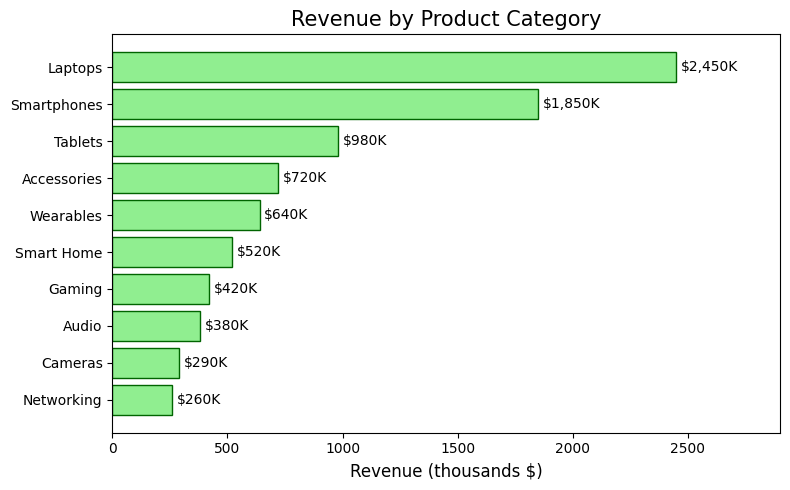

In [ ]:
# Sort so the largest bar is at the top
prod_sorted = products.sort_values('Revenue')
revenue_k = prod_sorted['Revenue'] / 1000  # thousands

fig, ax = plt.subplots(figsize=(8, 5))

# Horizontal bar chart with styling
ax.barh(prod_sorted['Category'], revenue_k, color='lightgreen', edgecolor='darkgreen')

# Data labels with revenue values
for i, v in enumerate(revenue_k):
    ax.text(v + 20, i, f'${v:,.0f}K', va='center')

ax.set_title('Revenue by Product Category', fontsize=15)
ax.set_xlabel('Revenue (thousands $)', fontsize=12)
ax.set_xlim(0, 2900)  # padding for labels

plt.tight_layout()
plt.show()

Task 2.2 Create a scatter plot showing the relationship between marketing spend and sales for each product
Use point size to represent the profit margin
Add a color gradient to represent ROI (Return on Investment)
Include a trend line
Add a title, axis labels, and a legend

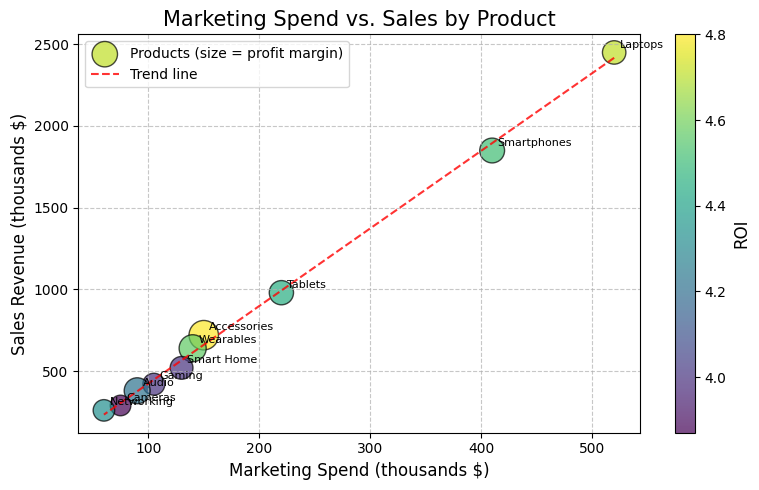

In [ ]:
spend = products['Marketing_Spend'] / 1000
revenue = products['Revenue'] / 1000

fig, ax = plt.subplots(figsize=(8, 5))

# Point size = profit margin, color gradient = ROI
scatter = ax.scatter(spend, revenue, s=products['Profit_Margin'] * 10,
                     c=products['ROI'], cmap='viridis', alpha=0.7, edgecolor='black',
                     label='Products (size = profit margin)')
cbar = plt.colorbar(scatter)
cbar.set_label('ROI', fontsize=12)

# Trend line
z = np.polyfit(spend, revenue, 1)
p = np.poly1d(z)
ax.plot(spend, p(spend), 'r--', alpha=0.8, label='Trend line')

# Label each point with its category
for i, name in enumerate(products['Category']):
    ax.text(spend[i] + 5, revenue[i] + 30, name, fontsize=8)

# Title, axis labels, and legend
ax.set_title('Marketing Spend vs. Sales by Product', fontsize=15)
ax.set_xlabel('Marketing Spend (thousands $)', fontsize=12)
ax.set_ylabel('Sales Revenue (thousands $)', fontsize=12)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Task 2.3 Create a pie chart showing the revenue distribution by product category
Add percentage labels
Explode the largest segment slightly
Include a title and legend

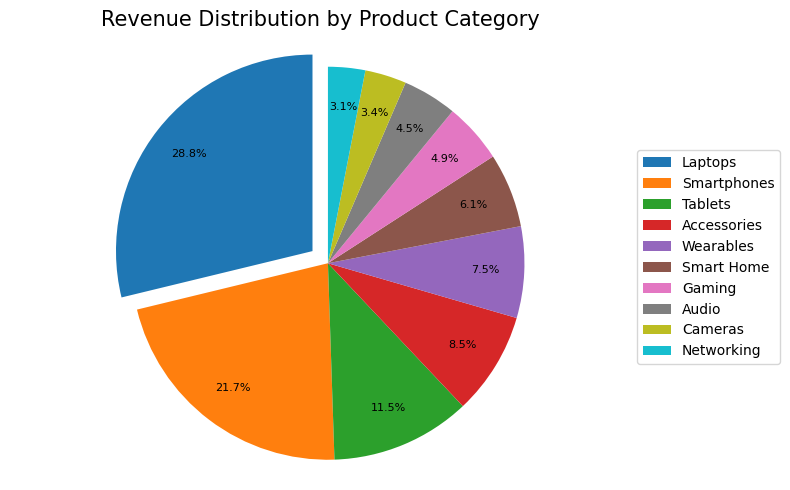

In [ ]:
prod_desc = products.sort_values('Revenue', ascending=False)

# Explode the largest slice
explode = [0.1, 0, 0, 0, 0, 0, 0, 0, 0, 0]

fig, ax = plt.subplots(figsize=(8, 5))

# Pie chart with percentage labels
wedges, texts, autotexts = ax.pie(prod_desc['Revenue'], explode=explode,
                                  autopct='%1.1f%%', startangle=90, pctdistance=0.8)
for autotext in autotexts:
    autotext.set_fontsize(8)

# Title and legend
ax.set_title('Revenue Distribution by Product Category', fontsize=15)
ax.legend(wedges, prod_desc['Category'], loc='center left', bbox_to_anchor=(1, 0.5))
ax.axis('equal')  # keeps the pie a circle

plt.tight_layout()
plt.show()

Task 3: Customer Segmentation Analysis

Task 3.1 Create a histogram showing the distribution of customer purchase amounts
Add vertical lines showing the mean and median
Use appropriate binning
Include a title and axis labels

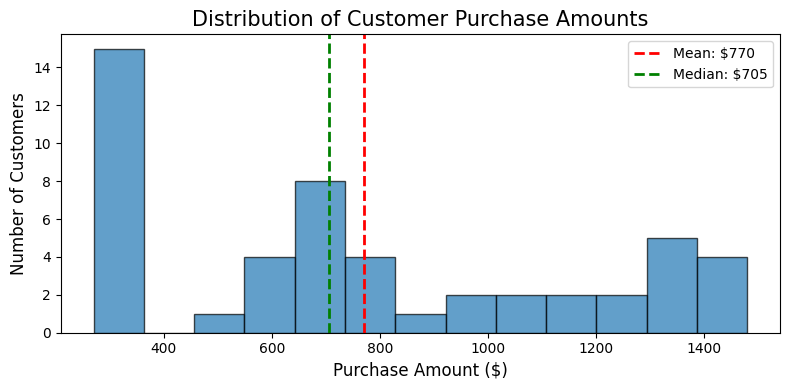

In [ ]:
amounts = customers['Purchase_Amount']

fig, ax = plt.subplots(figsize=(8, 4))

# Histogram
ax.hist(amounts, bins=13, edgecolor='black', alpha=0.7)

# Mean and median lines
ax.axvline(amounts.mean(), color='red', linestyle='dashed', linewidth=2,
           label=f'Mean: ${amounts.mean():.0f}')
ax.axvline(amounts.median(), color='green', linestyle='dashed', linewidth=2,
           label=f'Median: ${amounts.median():.0f}')

# Title and axis labels
ax.set_title('Distribution of Customer Purchase Amounts', fontsize=15)
ax.set_xlabel('Purchase Amount ($)', fontsize=12)
ax.set_ylabel('Number of Customers', fontsize=12)
ax.legend()

plt.tight_layout()
plt.show()

3.2 Create a bar chart comparing average purchase amounts by customer age group
Add error bars showing the standard deviation
Include a title and appropriate axis labels

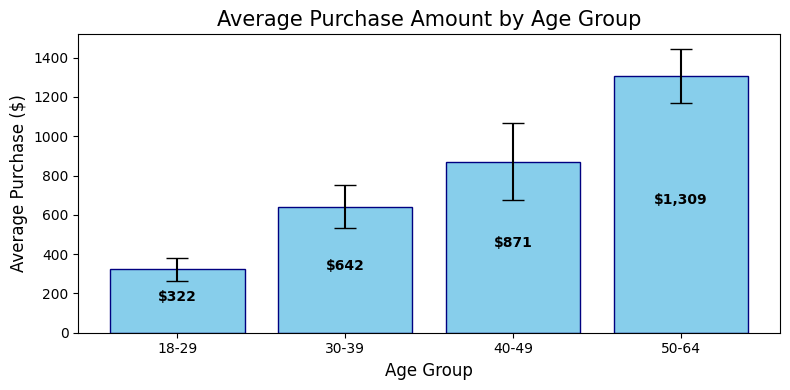

In [ ]:
# Put customers into age groups
customers['Age_Group'] = pd.cut(customers['Age'], bins=[18, 30, 40, 50, 65],
                                labels=['18-29', '30-39', '40-49', '50-64'], right=False)
avg = customers.groupby('Age_Group', observed=True)['Purchase_Amount'].mean()
std = customers.groupby('Age_Group', observed=True)['Purchase_Amount'].std()

fig, ax = plt.subplots(figsize=(8, 4))

# Bar chart with error bars
bars = ax.bar(avg.index.astype(str), avg.values, yerr=std.values, capsize=8,
              color='skyblue', edgecolor='navy')

# Data labels inside each bar
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height/2, f'${height:,.0f}',
            ha='center', fontweight='bold')

# Title and axis labels
ax.set_title('Average Purchase Amount by Age Group', fontsize=15)
ax.set_xlabel('Age Group', fontsize=12)
ax.set_ylabel('Average Purchase ($)', fontsize=12)

plt.tight_layout()
plt.show()

3.3 Create a grouped bar chart showing purchase frequency by customer segment and product category
Use different colors for each segment
Include a title, axis labels, and legend

In [ ]:
#Table of average purchase frequency
freq = customers.pivot_table(index='Product_Category', columns='Segment',
                             values='Purchase_Frequency', aggfunc='mean')
freq = freq[['New', 'Regular', 'Premium']]

fig, ax = plt.subplots(figsize=(9, 5))

# Grouped bar chart
freq.plot(kind='bar', ax=ax, color=['lightgreen', 'skyblue', 'navy'], edgecolor='black')

# Title, axis labels, and legend
ax.set_title('Purchase Frequency by Segment and Product Category', fontsize=15)
ax.set_xlabel('Product Category', fontsize=12)
ax.set_ylabel('Avg Purchases per Customer', fontsize=12)
ax.legend(title='Segment')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Task 4: Market Position Dashboard

Task 4.1 Create a figure with 4 subplots (2x2 grid)
Plot 1: Line chart showing market share trends over time
Plot 2: Pie chart showing current market share distribution
Plot 3: Bar chart comparing key performance metrics against competitors
Plot 4: Radar chart or another appropriate visualization showing strengths and weaknesses
Task 4.2 Apply appropriate styling to each subplot
Add titles to each subplot
Ensure consistent formatting and color schemes
Adjust subplot sizes and spacing for optimal visibility
Task 4.3 Add a figure suptitle (“TechTrends Market Position Analysis”)

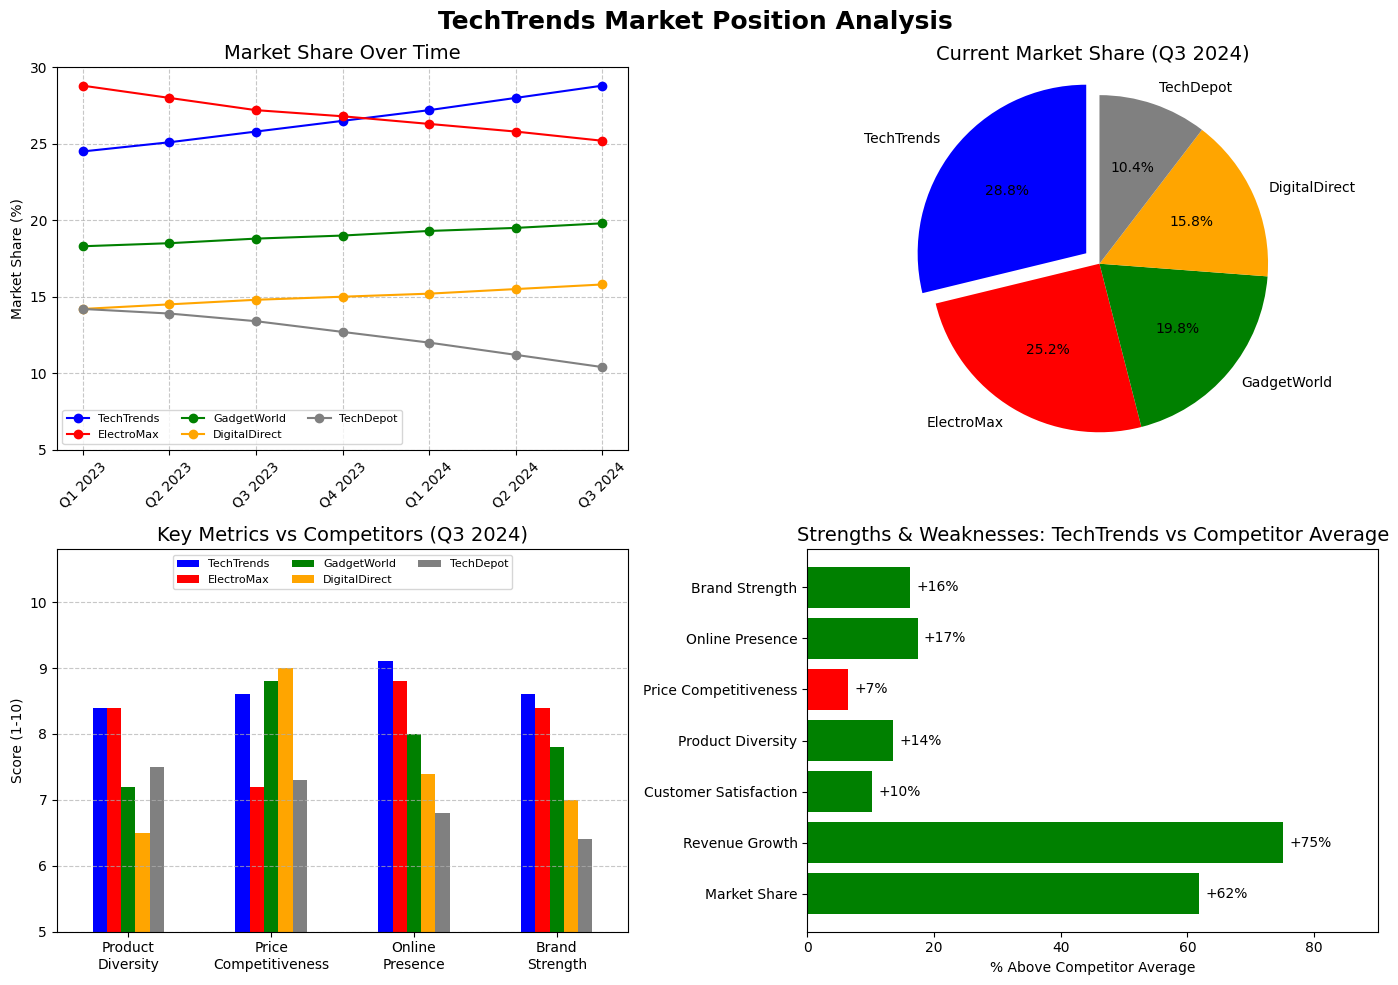

In [ ]:
# Pivot so each company is a column (pandas)
share = competitors.pivot(index='Quarter', columns='Company', values='Market_Share')
share = share.loc[competitors['Quarter'].unique()]  # keep quarters in time order
latest = competitors[competitors['Quarter'] == 'Q3 2024'].set_index('Company')

# Consistent colors
companies = ['TechTrends', 'ElectroMax', 'GadgetWorld', 'DigitalDirect', 'TechDepot']
colors = ['blue', 'red', 'green', 'orange', 'gray']

# 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Line chart
for company, color in zip(companies, colors):
    axes[0].plot(share.index, share[company], marker='o', color=color, label=company)
axes[0].set_title('Market Share Over Time', fontsize=14)
axes[0].set_ylabel('Market Share (%)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.7)
axes[0].set_ylim(5, 30)
axes[0].legend(fontsize=8, ncol=3, loc='lower left')

# Pie chart
axes[1].pie(latest.loc[companies, 'Market_Share'], labels=companies, colors=colors,
            autopct='%1.1f%%', startangle=90, explode=[0.1, 0, 0, 0, 0])
axes[1].set_title('Current Market Share (Q3 2024)', fontsize=14)
axes[1].axis('equal')

# Bar chart
metrics = ['Product_Diversity', 'Price_Competitiveness', 'Online_Presence', 'Brand_Strength']
latest.loc[companies, metrics].T.plot(kind='bar', ax=axes[2], color=colors)
axes[2].set_title('Key Metrics vs Competitors (Q3 2024)', fontsize=14)
axes[2].set_ylabel('Score (1-10)')
axes[2].set_ylim(5, 10.8)
axes[2].set_xticklabels(['Product\nDiversity', 'Price\nCompetitiveness',
                         'Online\nPresence', 'Brand\nStrength'], rotation=0)
axes[2].legend(fontsize=8, ncol=3, loc='upper center')
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

# Strengths & weaknesses
all_metrics = ['Market_Share', 'Revenue_Growth', 'Customer_Satisfaction',
               'Product_Diversity', 'Price_Competitiveness', 'Online_Presence',
               'Brand_Strength']
rivals_avg = latest.drop('TechTrends')[all_metrics].mean()
diff = (latest.loc['TechTrends', all_metrics] - rivals_avg) / rivals_avg * 100
bar_colors = ['red' if d == diff.min() else 'green' for d in diff]
axes[3].barh([m.replace('_', ' ') for m in all_metrics], diff, color=bar_colors)
for i, v in enumerate(diff):
    axes[3].text(v + 1, i, f'+{v:.0f}%', va='center')
axes[3].set_title('Strengths & Weaknesses: TechTrends vs Competitor Average', fontsize=14)
axes[3].set_xlabel('% Above Competitor Average')
axes[3].set_xlim(0, diff.max() * 1.2)

# Figure suptitle
fig.suptitle('TechTrends Market Position Analysis', fontsize=18, fontweight='bold')

# Adjust spacing between subplots
plt.tight_layout()

# Save the dashboard for the report
plt.savefig('market_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()